In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score

In [2]:
data = load_breast_cancer()

X = data.data
y = data.target

print("Dataset Shape:")
print(X.shape)

print("\nTarget Shape:")
print(y.shape)

Dataset Shape:
(569, 30)

Target Shape:
(569,)


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Train Shape:", X_train.shape)
print("Test Shape:", X_test.shape)

Train Shape: (455, 30)
Test Shape: (114, 30)


In [4]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [5]:
knn = KNeighborsClassifier()

log_reg = LogisticRegression(max_iter=5000)

svc = SVC(probability=True)

decision_tree = DecisionTreeClassifier()

In [6]:
knn.fit(X_train_scaled, y_train)

log_reg.fit(X_train_scaled, y_train)

svc.fit(X_train_scaled, y_train)

decision_tree.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [7]:
knn_pred = knn.predict(X_test_scaled)

log_pred = log_reg.predict(X_test_scaled)

svc_pred = svc.predict(X_test_scaled)

tree_pred = decision_tree.predict(X_test)

In [8]:
print("KNN Accuracy:",
      accuracy_score(y_test, knn_pred))

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, log_pred))

print("SVC Accuracy:",
      accuracy_score(y_test, svc_pred))

print("Decision Tree Accuracy:",
      accuracy_score(y_test, tree_pred))

KNN Accuracy: 0.9473684210526315
Logistic Regression Accuracy: 0.9736842105263158
SVC Accuracy: 0.9824561403508771
Decision Tree Accuracy: 0.9385964912280702


In [9]:
models = {
    "KNN": knn_pred,
    "Logistic Regression": log_pred,
    "SVC": svc_pred,
    "Decision Tree": tree_pred
}

for name, pred in models.items():

    print("\n", name)

    print("Precision:",
          precision_score(y_test, pred))

    print("Recall:",
          recall_score(y_test, pred))

    print("F1-Score:",
          f1_score(y_test, pred))


 KNN
Precision: 0.9577464788732394
Recall: 0.9577464788732394
F1-Score: 0.9577464788732394

 Logistic Regression
Precision: 0.9722222222222222
Recall: 0.9859154929577465
F1-Score: 0.9790209790209791

 SVC
Precision: 0.9726027397260274
Recall: 1.0
F1-Score: 0.9861111111111112

 Decision Tree
Precision: 0.9444444444444444
Recall: 0.9577464788732394
F1-Score: 0.951048951048951


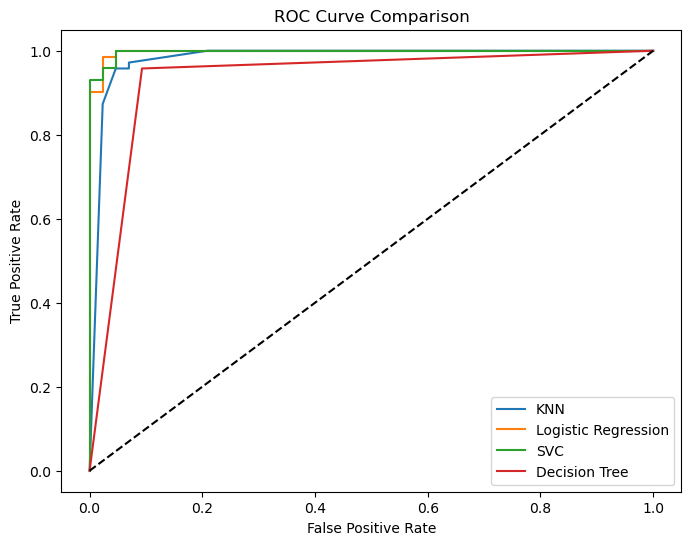

In [10]:
knn_prob = knn.predict_proba(X_test_scaled)[:,1]

log_prob = log_reg.predict_proba(X_test_scaled)[:,1]

svc_prob = svc.predict_proba(X_test_scaled)[:,1]

tree_prob = decision_tree.predict_proba(X_test)[:,1]


knn_fpr, knn_tpr, _ = roc_curve(y_test, knn_prob)

log_fpr, log_tpr, _ = roc_curve(y_test, log_prob)

svc_fpr, svc_tpr, _ = roc_curve(y_test, svc_prob)

tree_fpr, tree_tpr, _ = roc_curve(y_test, tree_prob)


plt.figure(figsize=(8,6))

plt.plot(knn_fpr, knn_tpr, label="KNN")

plt.plot(log_fpr, log_tpr, label="Logistic Regression")

plt.plot(svc_fpr, svc_tpr, label="SVC")

plt.plot(tree_fpr, tree_tpr, label="Decision Tree")

plt.plot([0,1], [0,1], 'k--')

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve Comparison")

plt.legend()

plt.show()

In [11]:
print("KNN AUC:",
      roc_auc_score(y_test, knn_prob))

print("Logistic Regression AUC:",
      roc_auc_score(y_test, log_prob))

print("SVC AUC:",
      roc_auc_score(y_test, svc_prob))

print("Decision Tree AUC:",
      roc_auc_score(y_test, tree_prob))

KNN AUC: 0.9819849328529315
Logistic Regression AUC: 0.99737962659679
SVC AUC: 0.99737962659679
Decision Tree AUC: 0.932361611529643
